# Global Supply Chain Bottleneck Analysis
**Analyst:** Prince Kumar

## The Business Problem
A global FMCG enterprise is suffering from a high rate of late deliveries, leading to tied-up capital and decreased customer satisfaction.

## Project Objective
Analyze 180,000+ historical shipping records to pinpoint the exact geographical regions and shipping modes causing the most severe bottlenecks, and quantify the financial impact of these delays.

## Methodology
Using Python and Pandas, the dataset is filtered to isolate 'Late delivery' statuses. The financial loss is calculated by aggregating the 'Order Item Total' for these delayed shipments across all global regions to identify the most critical points of failure.

Loading 180,000+ rows of supply chain data...
--------------------------------------------------
CRITICAL BOTTLENECK REPORT
--------------------------------------------------
Total Late Shipments Identified: 41,905
Total Revenue Trapped in Delays: $7,354,725.53
--------------------------------------------------


/tmp/ipykernel_755/3379306826.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


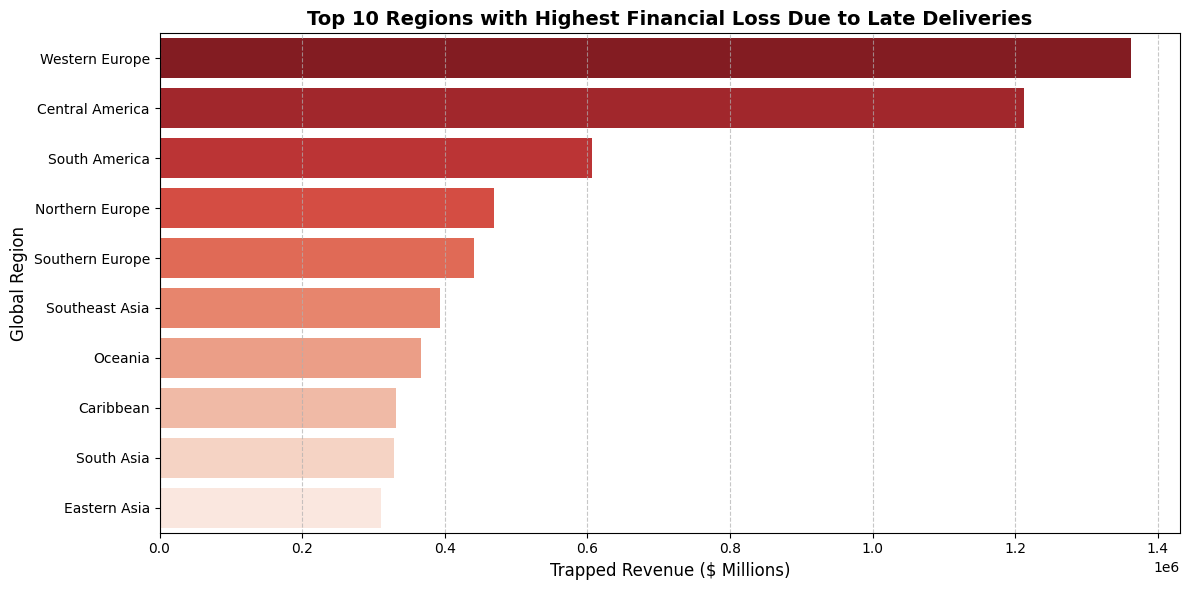


STRATEGIC RECOMMENDATION:
Immediate routing interventions required in Western Europe and Central America.
Action: Audit primary shipping carriers in these top two regions and model the cost-benefit of shifting 15% of Standard Class freight to First Class to protect at-risk revenue.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the massive dataset (using latin-1 encoding for this specific Kaggle file)
print("Loading 180,000+ rows of supply chain data...")
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin-1')

# 2. Data Cleaning & Feature Engineering
# Calculate the exact delay in days for every single shipment
df['Delivery_Delay_Days'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']

# Isolate only the orders that were officially marked as Late
late_deliveries = df[df['Delivery Status'] == 'Late delivery']

# 3. Financial Impact Analysis
# Group the late deliveries by region and sum up the total money trapped in these delays
financial_loss_by_region = late_deliveries.groupby('Order Region')['Order Item Total'].sum().reset_index()
financial_loss_by_region = financial_loss_by_region.sort_values(by='Order Item Total', ascending=False).head(10)

# 4. Print the high-level business metrics
total_late_orders = len(late_deliveries)
total_money_delayed = late_deliveries['Order Item Total'].sum()

print("-" * 50)
print(f"CRITICAL BOTTLENECK REPORT")
print("-" * 50)
print(f"Total Late Shipments Identified: {total_late_orders:,}")
print(f"Total Revenue Trapped in Delays: ${total_money_delayed:,.2f}")
print("-" * 50)

# 5. Visualizing the Bottlenecks
plt.figure(figsize=(12, 6))
sns.barplot(
    data=financial_loss_by_region,
    x='Order Item Total',
    y='Order Region',
    palette='Reds_r' # Uses a red gradient to signal financial danger
)

# Formatting the chart for a boardroom presentation
plt.title('Top 10 Regions with Highest Financial Loss Due to Late Deliveries', fontsize=14, fontweight='bold')
plt.xlabel('Trapped Revenue ($ Millions)', fontsize=12)
plt.ylabel('Global Region', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.savefig('Supply_Chain_Bottleneck_Chart.png', dpi=300, bbox_inches='tight')
# Show the chart
plt.show()

# 6. Strategic Recommendation Output
print("\nSTRATEGIC RECOMMENDATION:")
print(f"Immediate routing interventions required in {financial_loss_by_region.iloc[0]['Order Region']} and {financial_loss_by_region.iloc[1]['Order Region']}.")
print("Action: Audit primary shipping carriers in these top two regions and model the cost-benefit of shifting 15% of Standard Class freight to First Class to protect at-risk revenue.")